# Quanto do caminho de um animal marinho migratório passa por águas de algum país, e quanto por alto-mar?

Tartarugas, tubarões-baleia, elefantes-marinhos e albatrozes cruzam oceanos inteiros. Proteger a praia de desova ou
a colônia não protege a rota. A decisão que este estudo informa: para que espécies, e em que trechos de oceano, a
cooperação entre países (ou a proteção em alto-mar) importa mais.

O caminho: (1) reconstruir a trajetória de cada animal a partir de posições de satélite públicas; (2) medir a
fração do **tempo** em cada jurisdição, e não a fração dos registros; (3) dar a incerteza reamostrando animais
inteiros; (4) testar o viés do local de marcação; (5) comparar com uma caminhada aleatória.

É análise de dado público agregado, feita por um profissional de dados, não por um biólogo. As trajetórias são
reconstruídas em `scripts/baixar_dados.py` (as posições não podem ser versionadas); aqui a análise parte do extrato
agregado em `data/`.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from rotas_protecao import analise, dados, geodesia, graficos, trajetoria

pd.set_option("display.float_format", lambda v: f"{v:,.3f}")
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)
base = dados.carregar()
rng = np.random.default_rng(analise.SEMENTE)
nomes = {e: f["comum"] for e, f in base["especies"].items()}


def mostrar(figura):
    display(figura)
    plt.close(figura)


print("Coleta:", base["coleta"]["data_da_coleta"])

Coleta: 2026-11-12


## 1. Os dados: quem foi rastreado

O OBIS distribui rastreamentos por satélite como registros de ocorrência. Só servem os conjuntos que guardam o
identificador do animal. A tabela mostra os conjuntos usados, com a licença de cada um, e o funil de limpeza.

In [2]:
conjuntos = pd.DataFrame(base["coleta"]["conjuntos"]).T[["especie", "populacao", "registros", "licenca", "titulo"]]
display(conjuntos)
display(pd.DataFrame(base["coleta"]["funil"]).T.fillna(0).astype(int))
display(pd.DataFrame(analise.descricao(base)).T.drop(columns=["populacoes"]))

,especie,populacao,registros,licenca,titulo
couro_africa_sul_1,couro,África do Sul (Índico sudoeste),3630,CC BY 4.0,Leatherback Tracking in South Africa
couro_africa_sul_2,couro,África do Sul (Índico sudoeste),1841,CC BY-NC 4.0,Revealing migratory behaviour of South African leatherback turtles
cabecuda_pacifico_norte,cabecuda,Pacífico Norte,44085,CC BY-NC 4.0,NMFS Turtle Tracking
cabecuda_pacifico_juvenis,cabecuda,Pacífico Norte,6862,CC0,SWFSC juvenile loggerhead sea turtle tracking 2002-2005
cabecuda_taiwan,cabecuda,Pacífico Norte,5093,CC BY-NC 4.0,Loggerhead turtle movement off the coast of Taiwan
cabecuda_japao,cabecuda,Pacífico Norte,251,CC BY-NC 4.0,Adult female loggerhead turtles around Japan 1999
cabecuda_mediterraneo_oeste,cabecuda,Mediterrâneo,24125,CC BY 4.0,Satellite-tracking of loggerhead sea turtles tracked from western Mediterranean
cabecuda_creta,cabecuda,Mediterrâneo,3479,CC BY-NC 4.0,"Loggerhead satellite tracking data from Rethymno, Crete, Greece"
cabecuda_reuniao,cabecuda,Índico sudoeste,20139,CC BY-NC 4.0,IFREMER/Kélonia satellite tracked late juvenile loggerhead sea turtles from ...
cabecuda_mocambique,cabecuda,Índico sudoeste,1258,CC BY 4.0,AICM satellite tracked loggerhead sea turtles from Mozambique 2012 under SWIOFP


,registros_baixados,sem_ser_telemetria,sem_data_coordenada_ou_individuo,individuos_brutos,individuos_repetidos_entre_conjuntos,posicoes_usadas,posicoes_tiradas_pelo_filtro_de_velocidade,registros_dos_individuos_usados,individuos_usados,individuos_curtos_demais
couro,5471,0,0,29,0,4938,533,5471,29,0
cabecuda,105987,0,70,302,0,91779,13179,105853,293,9
baleia,5204,136,0,76,0,3052,11,4850,36,40
elefante,914197,437,0,437,0,913144,616,913760,437,0
albatroz,120821,253,0,253,0,117311,4,117315,220,33


,nome,cientifico,individuos,dias_rastreados,anos_de_animal,duracao_mediana_dias,duracao_p10_dias,duracao_p90_dias,registros,fracao_do_tempo_em_falhas,fracao_das_amostras_em_terra,passo_diario_mediano_km,distancia_maxima_mediana_km,ano_inicial,ano_final,conjuntos,marcados_em_alto_mar
albatroz,albatroz-errante,Diomedea exulans,220,"42,560.000",116.500,245.200,11.200,367.000,117315,0.000,0.005,253.700,"2,959.000",1997,2013,1,0.323
elefante,elefante-marinho-do-sul,Mirounga leonina,437,"76,074.000",208.300,183.800,67.000,281.800,913760,0.000,0.009,25.800,"1,733.000",1996,2013,1,0.382
couro,tartaruga-de-couro,Dermochelys coriacea,29,"2,955.000",8.100,109.500,43.600,155.900,5471,0.065,0.012,29.200,"1,393.000",1996,2013,2,0.000
cabecuda,tartaruga-cabeçuda,Caretta caretta,293,"62,748.000",171.800,162.500,48.200,463.100,105853,0.099,0.011,19.400,"1,837.000",1997,2018,9,0.188
baleia,tubarão-baleia,Rhincodon typus,36,"2,558.000",7.000,53.500,16.500,145.500,4850,0.888,0.000,26.500,"1,047.000",2011,2024,2,0.194


## 2. O método numa trajetória de brinquedo

Antes dos dados reais, o erro que o método evita. Um animal anda para leste no equador a 4 km/h: passa 100 horas de
um lado de uma fronteira e 100 horas do outro, mas o transmissor manda dez vezes mais posições no primeiro trecho.
A contagem de posições diz que ele quase não esteve do outro lado; a interpolação regular no tempo devolve a
metade.

In [3]:
grau_km = 2 * np.pi * geodesia.RAIO_KM / 360
horas = np.concatenate([np.arange(0, 100, 1.0), np.arange(100, 201, 10.0)])
lon = horas * 4.0 / grau_km
fronteira = 100 * 4.0 / grau_km
regular = trajetoria.interpolar_regular(horas, np.zeros_like(horas), lon, passo_h=1.0)
print(f"fração além da fronteira, contando posições: {np.mean(lon >= fronteira):.1%}")
print(f"fração além da fronteira, pelo tempo:        {np.mean(regular['lon'] >= fronteira):.1%}")

fração além da fronteira, contando posições: 9.9%
fração além da fronteira, pelo tempo:        50.0%


## 3. Tempo, não pontos

Para cada espécie: a fração em alto-mar pelo tempo rastreado (amostras de 6 horas ao longo da trajetória, sem
interpolar por cima de falhas de mais de 10 dias) e pela contagem dos registros brutos. O intervalo do método
reamostra animais inteiros. A tabela mostra também o intervalo ingênuo, que trata cada registro como independente.

,individuos,tempo,tempo_inf,tempo_sup,pontos,pontos_inf_ingenuo,pontos_sup_ingenuo,diferenca,diferenca_inf,diferenca_sup
nome,,,,,,,,,,
albatroz-errante,220,0.726,0.704,0.748,0.669,0.666,0.672,0.057,0.037,0.080
elefante-marinho-do-sul,437,0.823,0.797,0.846,0.822,0.822,0.823,0.000,0.000,0.000
tartaruga-de-couro,29,0.282,0.164,0.412,0.266,0.254,0.277,0.017,-0.048,0.081
tartaruga-cabeçuda,293,0.649,0.597,0.695,0.481,0.478,0.484,0.168,0.126,0.207
tubarão-baleia,36,0.225,0.119,0.366,0.249,0.238,0.262,-0.024,-0.093,0.035


,diferenca,erro_dentro_de_cada_animal,erro_de_quem_transmite_mais
nome,,,
albatroz-errante,0.057,-0.000,0.057
elefante-marinho-do-sul,0.000,0.000,0.000
tartaruga-de-couro,0.017,0.003,0.014
tartaruga-cabeçuda,0.168,-0.004,0.172
tubarão-baleia,-0.024,-0.007,-0.018


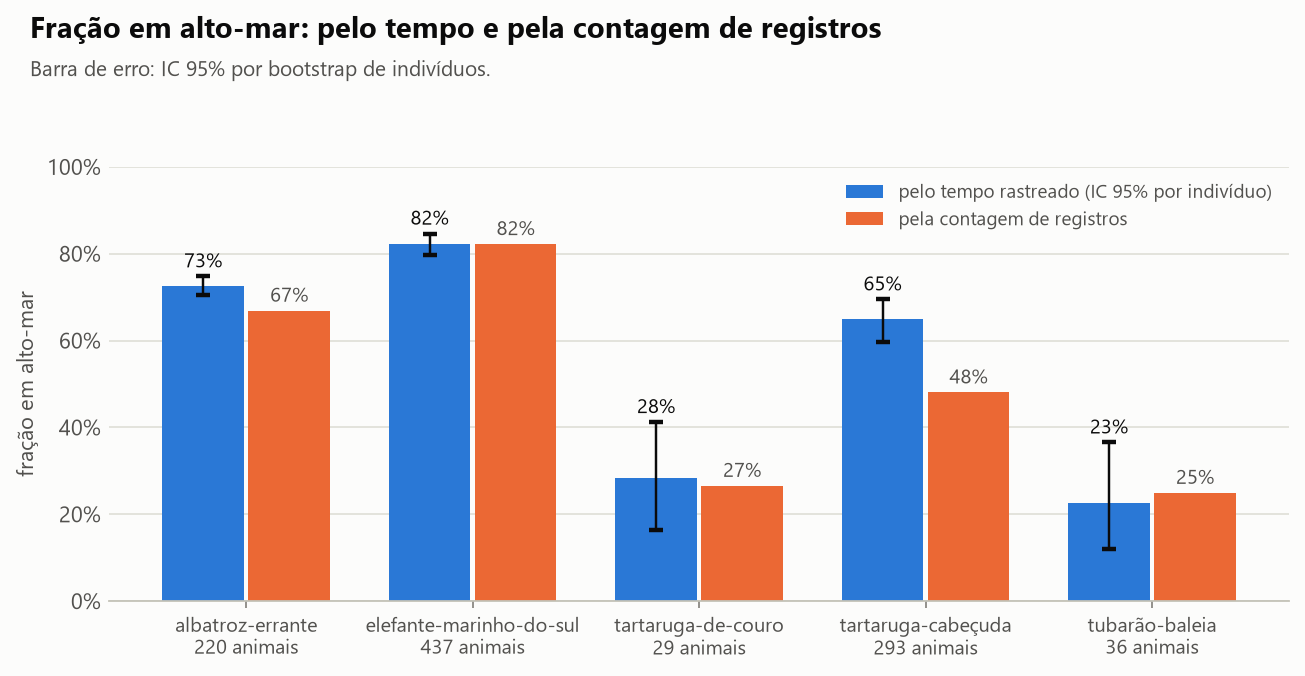

In [4]:
alto_mar = analise.alto_mar_por_especie(base, rng)
display(alto_mar.set_index("nome")[["individuos", "tempo", "tempo_inf", "tempo_sup", "pontos", "pontos_inf_ingenuo", "pontos_sup_ingenuo", "diferenca", "diferenca_inf", "diferenca_sup"]])
# De onde vem a diferença: de dentro de cada trajetória, ou de quem transmite mais pesar mais?
display(alto_mar.set_index("nome")[["diferenca", "erro_dentro_de_cada_animal", "erro_de_quem_transmite_mais"]])
mostrar(graficos.tempo_x_pontos(alto_mar, "Fração em alto-mar: pelo tempo e pela contagem de registros", "Barra de erro: IC 95% por bootstrap de indivíduos."))

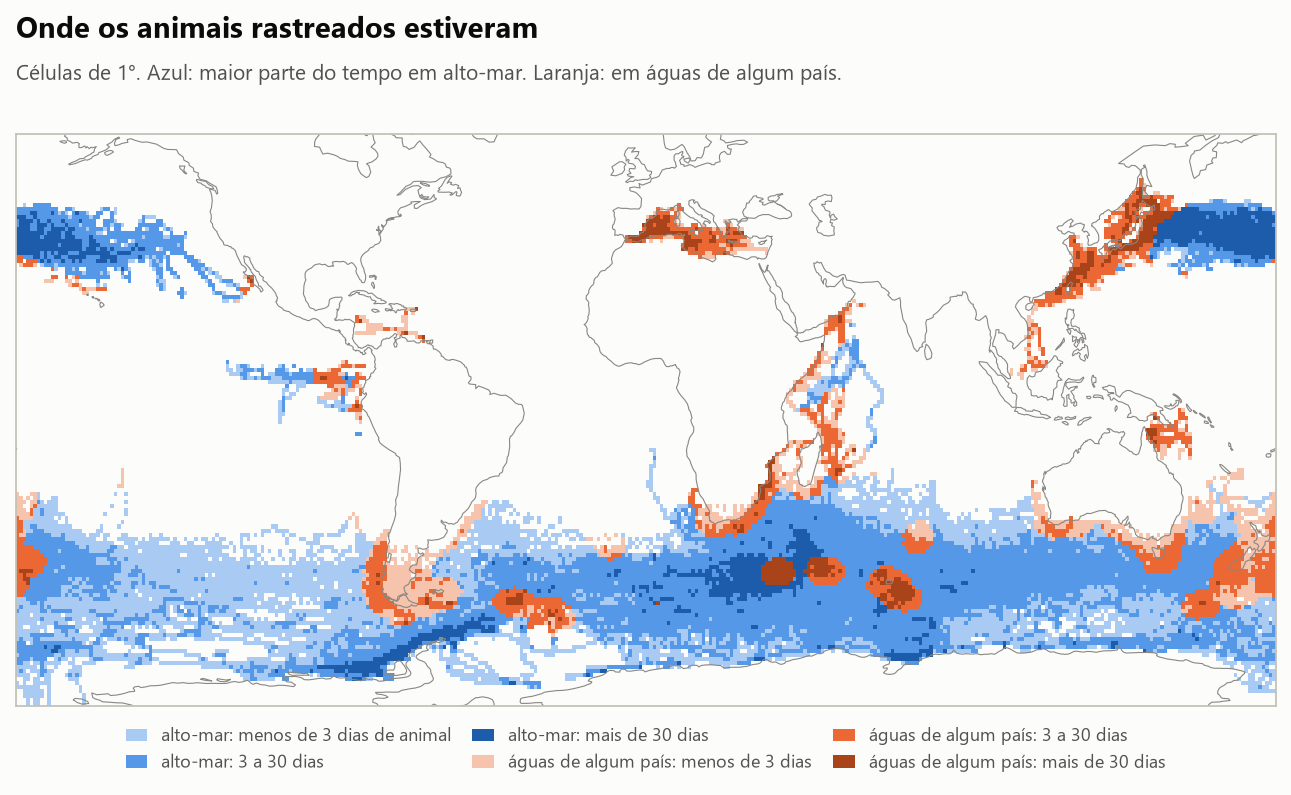

In [5]:
mostrar(graficos.mapa_do_tempo(base["grade_1grau"], base["costa"], "Onde os animais rastreados estiveram", "Células de 1°. Azul: maior parte do tempo em alto-mar. Laranja: em águas de algum país."))

## 4. Em que jurisdições

A tabela completa está em `reports/tempo_por_jurisdicao.csv`. Abaixo, as seis primeiras de cada espécie.

tipo  \
nome_comum              jurisdicao                                                             
albatroz-errante        Alto-mar                                                    alto-mar   
                        França                                                           ZEE   
                        Nova Zelândia                                                    ZEE   
                        África do Sul                                                    ZEE   
                        Austrália                                                        ZEE   
                        Chile                                                            ZEE   
tubarão-baleia          Austrália                                                        ZEE   
                        Alto-mar                                                    alto-mar   
                        Equador                                                          ZEE   
                        Papua-Nova Guiné                                                 ZEE   
                        Peru                                                             ZEE   
                        Costa Rica                                                       ZEE   
tartaruga-cabeçuda      Alto-mar                                                    alto-mar   
                        Japão                                                            ZEE   
                        Espanha                                                          ZEE   
                        China                                                            ZEE   
                        Grécia                                                           ZEE   
                        Tunísia                                                          ZEE   
tartaruga-de-couro      África do Sul                                                    ZEE   
                        Moçambique                                                       ZEE   
                        Alto-mar                                                    alto-mar   
                        Namíbia                                                          ZEE   
                        Madagascar                                                       ZEE   
                        França                                                           ZEE   
elefante-marinho-do-sul Alto-mar                                                    alto-mar   
                        Área em disputa: Argentina / Reino Unido  disputa ou regime conjunto   
                        África do Sul                                                    ZEE   
                        França                                                           ZEE   
                        Austrália                                                        ZEE   
                        Reino Unido                                                      ZEE   

                                                                  fracao_do_tempo  \
nome_comum              jurisdicao                                                  
albatroz-errante        Alto-mar                                            0.726   
                        França                                              0.081   
                        Nova Zelândia                                       0.065   
                        África do Sul                                       0.046   
                        Austrália                                           0.046   
                        Chile                                               0.020   
tubarão-baleia          Austrália                                           0.364   
                        Alto-mar                                            0.225   
                        Equador                                             0.165   
                        Papua-Nova Guiné                                    0.15

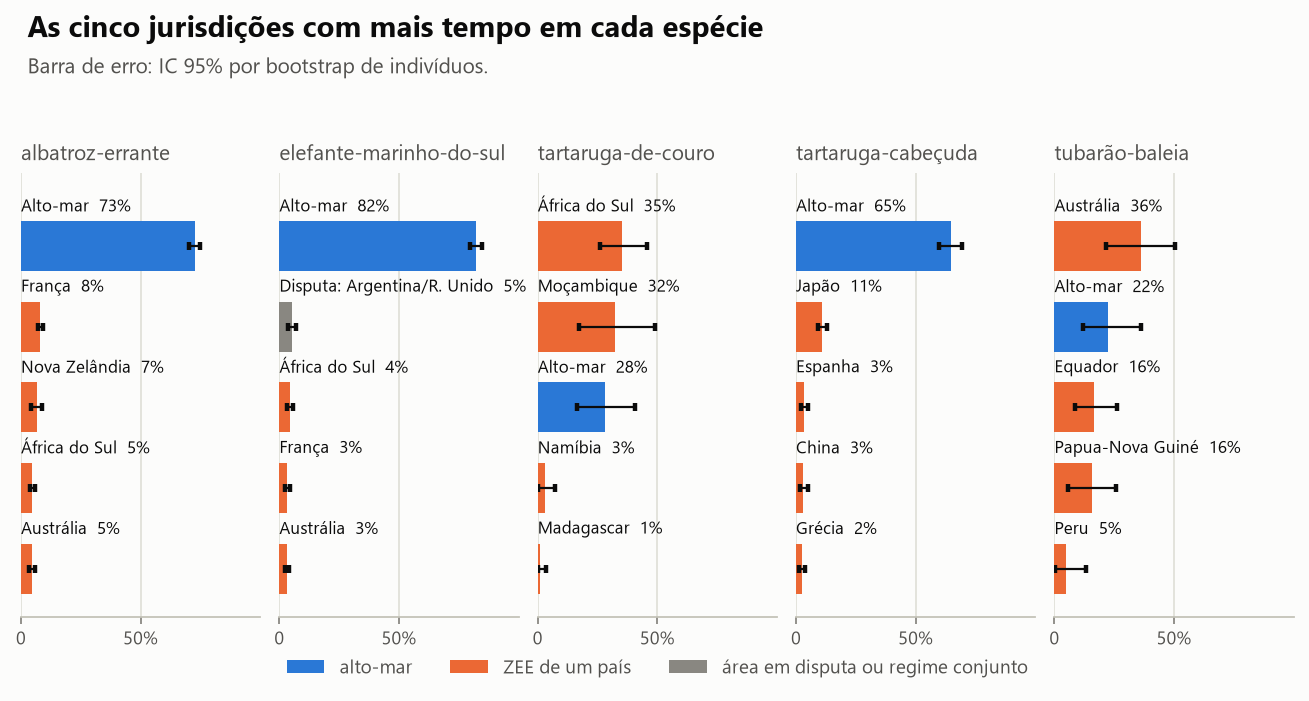

In [6]:
jurisdicoes = analise.tempo_por_jurisdicao(base, rng)
display(jurisdicoes.groupby("chave_especie", sort=False).head(6).set_index(["nome_comum", "jurisdicao"])[["tipo", "fracao_do_tempo", "ic95_inferior", "ic95_superior", "fracao_dos_registros", "individuos_que_usaram"]])
mostrar(graficos.jurisdicoes(jurisdicoes, analise.ORDEM, "As cinco jurisdições com mais tempo em cada espécie", "Barra de erro: IC 95% por bootstrap de indivíduos."))

## 5. O viés de onde se marca

Os animais são marcados perto da costa: na praia de desova, na colônia, no ponto de agregação. O começo de toda
trajetória é costeiro por construção. Dois testes: a curva semana a semana desde a marcação, e a fração em alto-mar
refeita descartando os primeiros 14, 28 e 56 dias de cada animal.

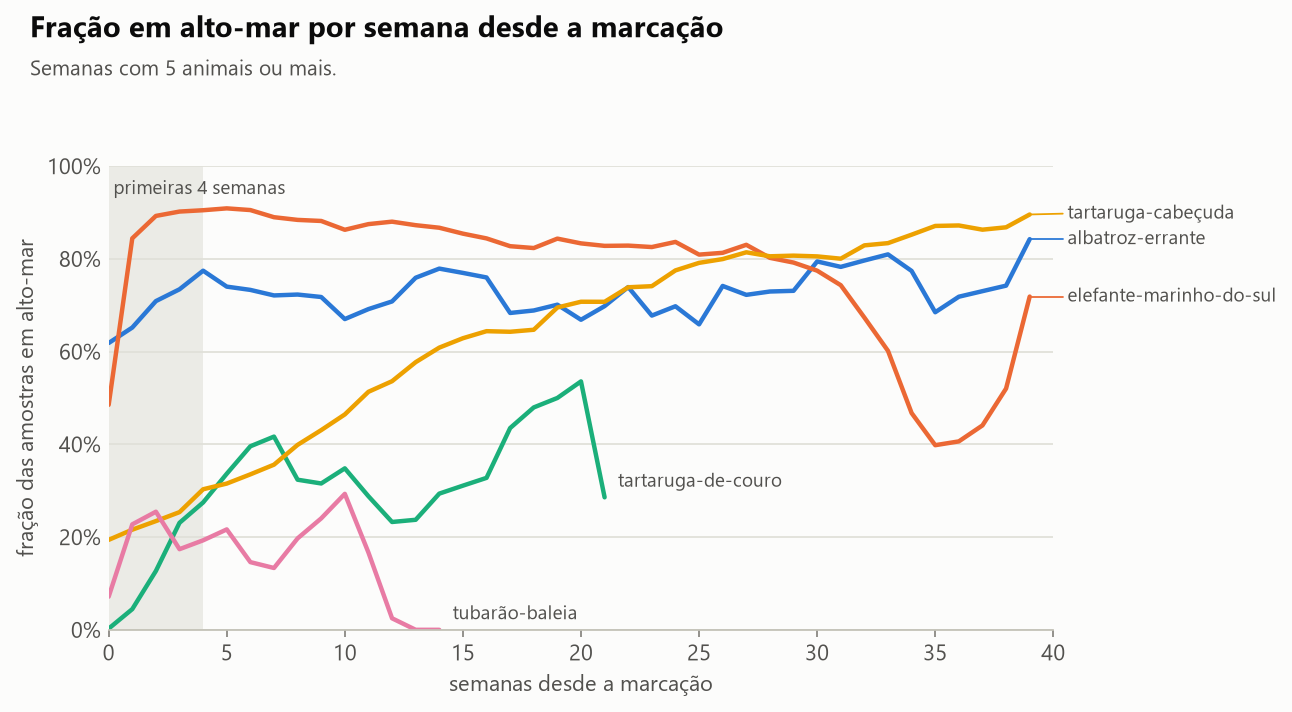

dias_descartados,0,14,28,56
especie,,,,
albatroz,0.726,0.733,0.734,0.733
elefante,0.823,0.836,0.831,0.814
couro,0.282,0.322,0.347,0.344
cabecuda,0.649,0.678,0.707,0.762
baleia,0.225,0.237,0.240,0.253


dias_descartados,0,14,28,56
especie,,,,
albatroz,220,170,130,125
elefante,437,434,430,412
couro,29,29,27,24
cabecuda,293,290,280,263
baleia,36,33,32,27


In [7]:
mostrar(graficos.curva_desde_a_marcacao(analise.curva_semanal(base), nomes, "Fração em alto-mar por semana desde a marcação", "Semanas com 5 animais ou mais."))
marcacao = analise.vies_de_marcacao(base, rng)
display(marcacao.pivot(index="especie", columns="dias_descartados", values="estimativa").loc[analise.ORDEM])
display(marcacao.pivot(index="especie", columns="dias_descartados", values="individuos").loc[analise.ORDEM])

## 6. Duração desigual, falhas de transmissão e populações

Três perguntas de robustez: o número muda se a regra para falhas de transmissão for outra? Muda se só entrarem
animais rastreados por muito tempo, ou se cada animal pesar igual? E muda de uma população para outra da mesma
espécie?

In [8]:
sens = analise.sensibilidade(base, rng)
display(sens.pivot(index="variante", columns="especie", values="estimativa")[analise.ORDEM])
display(analise.duracao_e_alto_mar(base).set_index("especie"))
display(analise.por_populacao(base, rng).set_index(["especie", "populacao"]))

especie,albatroz,elefante,couro,cabecuda,baleia
variante,,,,,
falha máxima de 3 dias,0.726,0.823,0.299,0.571,0.249
interpolando por cima de qualquer falha,0.726,0.823,0.270,0.640,0.329
média por indivíduo (cada animal pesa igual),0.648,0.828,0.259,0.447,0.307
"principal: falha máxima de 10 dias, tempo somado",0.726,0.823,0.282,0.649,0.225
só animais com 180 dias ou mais,0.736,0.817,NaN,0.764,NaN
só animais com 30 dias ou mais,0.732,0.822,0.286,0.652,0.212
só animais com 90 dias ou mais,0.734,0.822,0.251,0.685,0.088


,spearman,p_valor,alto_mar_dos_mais_curtos,alto_mar_dos_mais_longos,duracao_mediana_dias
especie,,,,,
albatroz,0.246,0.000,0.669,0.732,245.250
elefante,-0.084,0.079,0.843,0.814,183.750
couro,0.206,0.283,0.332,0.263,109.500
cabecuda,0.540,0.000,0.254,0.745,162.500
baleia,-0.217,0.204,0.375,0.182,53.500


individuos  dias_de_animal  \
especie  populacao                                                     
albatroz Oceano Austral                          220      42,559.500   
elefante Oceano Austral                          437      76,073.750   
couro    África do Sul (Índico sudoeste)          29       2,955.000   
cabecuda Caribe                                    4         365.500   
         Mediterrâneo                             59       6,842.250   
         Pacífico Norte                          210      52,642.500   
         Índico sudoeste                          20       2,897.500   
baleia   Galápagos (Pacífico leste)               21       1,222.000   
         Mar de Coral (Pacífico oeste)            15       1,335.750   

                                          estimativa  inferior  superior  
especie  populacao                                                        
albatroz Oceano Austral                        0.726     0.703     0.748  
elefante Oceano Austral                        0.823     0.798     0.846  
couro    África do Sul (Índico sudoeste)       0.282     0.155     0.411  
cabecuda Caribe                                0.000     0.000     0.000  
         Mediterrâneo                          0.000     0.000     0.000  
         Pacífico Norte                        0.758     0.712     0.797  
         Índico sudoeste                       0.284     0.156     0.419  
baleia   Galápagos (Pacífico leste)            0.471     0.315     0.653  
         Mar de Coral (Pacífico oeste)         0.000     0.000     0.000

## 7. Quantas jurisdições um animal usa, e quem compartilha animais com quem

,individuos,media,mediana,maximo,nenhuma,uma,duas_ou_mais,tres_ou_mais,mais_de_um_regime
especie,,,,,,,,,
albatroz,220,2.518,2.000,8,0.027,0.327,0.645,0.427,0.959
elefante,437,1.034,1.000,3,0.192,0.586,0.222,0.005,0.799
couro,29,1.828,2.000,4,0.000,0.310,0.690,0.103,0.966
cabecuda,293,2.024,2.000,8,0.160,0.331,0.509,0.324,0.724
baleia,36,1.611,1.000,6,0.056,0.528,0.417,0.139,0.667


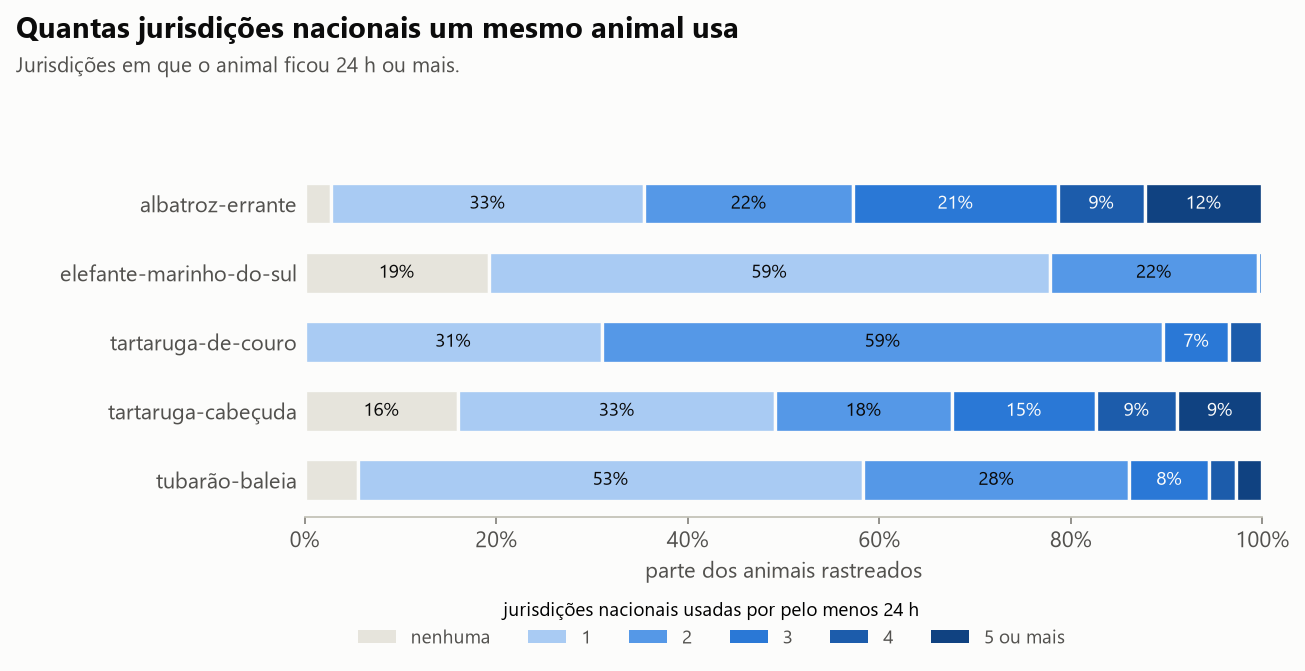

,especie,jurisdicao_a,jurisdicao_b,individuos_em_comum,individuos_em_a,individuos_em_b
0,albatroz,França,Austrália,89,119,99
1,albatroz,França,África do Sul,87,119,112
2,elefante,França,Austrália,66,89,111
3,albatroz,Austrália,África do Sul,57,99,112
4,albatroz,Austrália,Nova Zelândia,48,99,50
5,albatroz,França,Nova Zelândia,43,119,50
6,cabecuda,Japão,Área em disputa: Japão / Rússia,36,143,36
7,cabecuda,Rússia,Japão,28,28,143
8,cabecuda,Japão,Área em disputa: China / Taiwan,25,143,31
9,cabecuda,Japão,Área em disputa: Japão / Taiwan,25,143,28


,especie,entre,e,travessias
0,albatroz,Alto-mar,França,1832
1,albatroz,Alto-mar,África do Sul,1142
2,albatroz,Alto-mar,Austrália,905
3,albatroz,Alto-mar,Nova Zelândia,663
4,elefante,Alto-mar,África do Sul,266
5,elefante,Alto-mar,Área em disputa: Argentina / Reino Unido,199
6,elefante,Alto-mar,Austrália,166
7,albatroz,França,Austrália,163
8,elefante,França,Austrália,141
9,albatroz,Alto-mar,Área em disputa: Argentina / Reino Unido,136


In [9]:
por_animal = analise.jurisdicoes_por_individuo(base)
display(por_animal.drop(columns=["distribuicao"]).set_index("especie"))
mostrar(graficos.jurisdicoes_por_animal(por_animal, nomes, analise.ORDEM, "Quantas jurisdições nacionais um mesmo animal usa", "Jurisdições em que o animal ficou 24 h ou mais."))
display(analise.conexoes(base).head(15))
display(analise.travessias(base).head(15))

## 8. Contra o acaso

A hipótese nula: um animal que sai do mesmo ponto de marcação e dá passos do mesmo tamanho, sem destino. Duas
versões: sem memória (cada passo num rumo qualquer) e com persistência (os giros do próprio animal). Se o animal
real usa mais o alto-mar do que as caminhadas, o alto-mar não é só consequência de andar muito.

individuos  observado  acaso  diferenca  \
especie  caminhada                                                   
albatroz sem memória              220      0.727  0.769     -0.042   
         com persistência         220      0.727  0.758     -0.031   
elefante sem memória              437      0.823  0.597      0.226   
         com persistência         437      0.823  0.722      0.101   
couro    sem memória               29      0.283  0.113      0.170   
         com persistência          29      0.283  0.249      0.034   
cabecuda sem memória              293      0.649  0.283      0.367   
         com persistência         293      0.649  0.335      0.314   
baleia   sem memória               36      0.228  0.095      0.133   
         com persistência          36      0.228  0.181      0.047   

                           diferenca_inf  diferenca_sup  \
especie  caminhada                                        
albatroz sem memória              -0.060         -0.025   
         com persistência         -0.052         -0.012   
elefante sem memória               0.192          0.261   
         com persistência          0.077          0.125   
couro    sem memória               0.075          0.274   
         com persistência         -0.057          0.132   
cabecuda sem memória               0.316          0.415   
         com persistência          0.272          0.352   
baleia   sem memória               0.028          0.264   
         com persistência         -0.032          0.136   

                           individuos_acima_do_acaso  
especie  caminhada                                    
albatroz sem memória                           0.364  
         com persistência                      0.409  
elefante sem memória                           0.723  
         com persistência                      0.700  
couro    sem memória                           0.483  
         com persistência                      0.345  
cabecuda sem memória                           0.430  
         com persistência                      0.468  
baleia   sem memória                           0.417  
         com persistência                      0.389

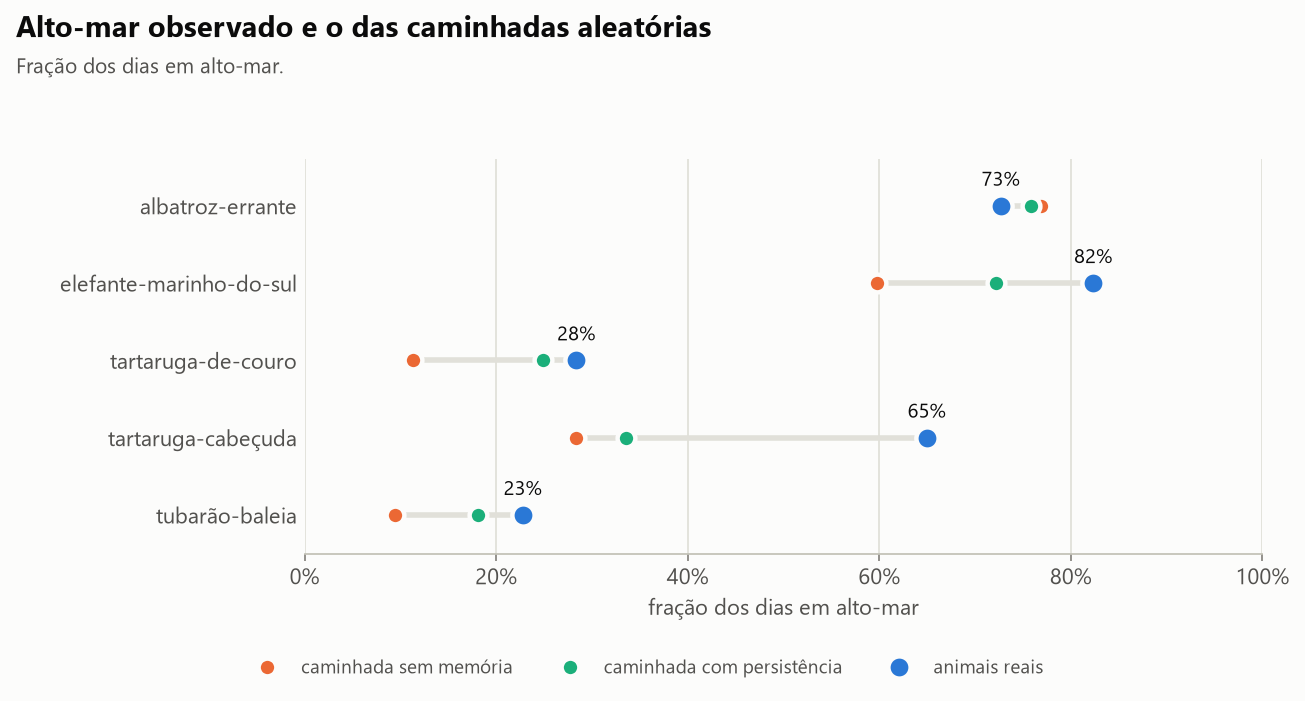

In [10]:
acaso = analise.contra_o_acaso(base, rng)
display(acaso.set_index(["especie", "caminhada"]))
mostrar(graficos.observado_x_acaso(acaso, nomes, analise.ORDEM, "Alto-mar observado e o das caminhadas aleatórias", "Fração dos dias em alto-mar."))

## 9. Os trechos de alto-mar mais usados

In [11]:
display(analise.trechos_de_alto_mar(base).set_index(["especie", "bloco"]))
display(analise.concentracao_do_alto_mar(base).set_index("especie"))

oceano  dias_em_alto_mar  \
especie  bloco                                                        
albatroz 40° a 50°S, 40° a 50°L        Índico Sul         2,183.250   
         30° a 40°S, 40° a 50°L            Índico         2,013.250   
         50° a 60°S, 40° a 50°L    Oceano Austral         1,564.250   
elefante 60° a 70°S, 70° a 80°O    Oceano Austral         5,907.750   
         60° a 70°S, 50° a 60°O    Oceano Austral         5,138.000   
         60° a 70°S, 60° a 70°O    Oceano Austral         3,834.250   
couro    30° a 40°S, 30° a 40°L            Índico           236.500   
         30° a 40°S, 10° a 20°L     Atlântico Sul           172.750   
         30° a 40°S, 20° a 30°L            Índico            92.750   
cabecuda 30° a 40°N, 170° a 180°L  Pacífico Norte         7,669.500   
         30° a 40°N, 170° a 180°O  Pacífico Norte         5,046.000   
         30° a 40°N, 160° a 170°L  Pacífico Norte         5,027.500   
baleia   0° a 10°N, 100° a 110°O   Pacífico Norte           165.250   
         0° a 10°N, 90° a 100°O    Pacífico Norte           127.250   
         0° a 10°N, 80° a 90°O     Pacífico Norte            87.000   

                                   parte_do_alto_mar_da_especie  \
especie  bloco                                                    
albatroz 40° a 50°S, 40° a 50°L                           0.071   
         30° a 40°S, 40° a 50°L                           0.065   
         50° a 60°S, 40° a 50°L                           0.051   
elefante 60° a 70°S, 70° a 80°O                           0.094   
         60° a 70°S, 50° a 60°O                           0.082   
         60° a 70°S, 60° a 70°O                           0.061   
couro    30° a 40°S, 30° a 40°L                           0.283   
         30° a 40°S, 10° a 20°L                           0.207   
         30° a 40°S, 20° a 30°L                           0.111   
cabecuda 30° a 40°N, 170° a 180°L                         0.188   
         30° a 40°N, 170° a 180°O                         0.124   
         30° a 40°N, 160° a 170°L                         0.123   
baleia   0° a 10°N, 100° a 110°O                          0.287   
         0° a 10°N, 90° a 100°O                           0.221   
         0° a 10°N, 80° a 90°O                            0.151   

                                   parte_do_tempo_da_especie  \
especie  bloco                                                 
albatroz 40° a 50°S, 40° a 50°L                        0.051   
         30° a 40°S, 40° a 50°L                        0.047   
         50° a 60°S, 40° a 50°L                        0.037   
elefante 60° a 70°S, 70° a 80°O                        0.078   
         60° a 70°S, 50° a 60°O                        0.068   
         60° a 70°S, 60° a 70°O                        0.050   
couro    30° a 40°S, 30° a 40°L                        0.080   
         30° a 40°S, 10° a 20°L                        0.058   
         30° a 40°S, 20° a 30°L                        0.031   
cabecuda 30° a 40°N, 170° a 180°L                      0.122   
         30° a 40°N, 170° a 180°O                      0.080   
         30° a 40°N, 160° a 170°L                      0.080   
baleia   0° a 10°N, 100° a 110°O                       0.065   
         0° a 10°N, 90° a 100°O                        0.050   
         0° a 10°N, 80° a 90°O                         0.034   

                                   individuos_na_celula_mais_usada  
especie  bloco                                                      
albatroz 40° a 50°S, 40° a 50°L                                 64  
         30° a 40°S, 40° a 50°L                                 52  
         50° a 60°S, 40° a 50°L                                 38  
elefante 60° a 70°S, 70° a 80°O                                 57  
         60° a 70°S, 50° a 60°O                                 56  
         60° a 70°S, 60° a 70°O                                 73  
couro    30° a 40°S, 30° a 40°L                       

,celulas_com_alto_mar,celulas_para_metade_do_tempo
especie,,
albatroz,7845,916
elefante,6008,421
couro,291,52
cabecuda,1498,236
baleia,142,23


## 10. O que levar daqui

- A resposta muda muito de uma espécie para outra, e dentro da mesma espécie de uma população para outra.
- Contar registros em vez de tempo empata em três das cinco espécies. Onde erra, o erro quase todo vem de animais
  com transmissor mais falante pesarem mais, e não de dentro de cada trajetória.
- O intervalo por indivíduo é muito mais largo do que o que se obtém tratando cada posição como independente.
- Contra a caminhada aleatória, o albatroz-errante usa o alto-mar um pouco menos do que o acaso: ele sempre volta
  à colônia. Uma hipótese nula sem retorno é ruim para animais assim, e o README diz isso.
- O README lista onde o estudo falha e o que faltaria para isto virar contribuição científica.